In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


# Install Dependencies

In [ ]:
!pip install -q transformers datasets accelerate evaluate scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.8 MB/s eta 0:00:00


# Import Dependencies

In [ ]:
import pandas as pd
import numpy as np
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support


# Define File Paths & Configurations

In [ ]:
DATA_PATH = '/content/drive/MyDrive/Assamese_Sentiment_Analysis/Data/Assamese_Movie_Review_Cleaned_8987.csv'
MODEL_NAME = 'google/muril-base-cased'
OUTPUT_DIR = '/content/drive/MyDrive/Assamese_Sentiment_Analysis/Models/muril/muril_finetuned'


# Load Cleaned Dataset

In [ ]:
df = pd.read_csv(DATA_PATH)

print(df.shape)
df.head()


(8987, 3)


,ID,Reviews,Sentiment
0,0,বোকা নাটক,negative
1,1,নাটকখন বৰ ধুনীয়া আছিল,positive
2,2,এখন ভাল ঘৰ এনে হব লাগে,positive
3,3,এইটো আশ্চৰ্যকৰ আছিল,positive
4,4,মই বহুদিন অপেক্ষা কৰি আছো. অৱশেষত দেখিলো. কেৱল...,positive


In [ ]:
df['Sentiment'].value_counts(dropna=False)


,count
Sentiment,
positive,5677
negative,3309
NaN,1


In [ ]:
# Show the problematic sentiment entries
df.loc[df['label'].isna(), 'Sentiment'].value_counts(dropna=False)


,count
Sentiment,
nan,1


In [ ]:
df[df['label'].isna()]['Sentiment'].unique()


array([nan], dtype=object)

In [ ]:
# Remove corrupted row with header leakage
df = df[~((df['ID'] == 4227) & (df['Reviews'] == 'Reviews'))].reset_index(drop=True)

print("Dataset shape after removing corrupted row:", df.shape)


Dataset shape after removing corrupted row: (8986, 4)


In [ ]:
assert not ((df['Reviews'] == 'Reviews') | (df['Sentiment'].isna())).any(), \
    "Corrupted rows still exist in the dataset"


# Encode Sentiment Labels (Model-Specific)

In [ ]:
df['Sentiment'] = (
    df['Sentiment']
    .astype(str)
    .str.strip()
    .str.lower()
)

label_map = {'negative': 0, 'positive': 1}
df['label'] = df['Sentiment'].map(label_map)

df = df.dropna(subset=['label']).reset_index(drop=True)

assert df['label'].isna().sum() == 0


# Pre-tokenization Normalization

In [ ]:
# Ensure all reviews are strings (critical for tokenizers)
df['Reviews'] = df['Reviews'].astype(str)

# Remove empty or whitespace-only reviews
df = df[df['Reviews'].str.strip() != ""].reset_index(drop=True)

# Sanity checks
assert df['Reviews'].isna().sum() == 0, "NaN found in Reviews"
assert df['label'].isna().sum() == 0, "NaN found in labels"

print("Pre-tokenization normalization completed")
print("Dataset shape:", df.shape)


Pre-tokenization normalization completed
Dataset shape: (8986, 4)


# Train-Test-Validation Split

In [ ]:
train_texts, val_texts, train_labels, val_labels = train_test_split(
    df['Reviews'].tolist(),
    df['label'].tolist(),
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)

len(train_texts), len(val_texts)


(7188, 1798)

In [ ]:
# Ensure all reviews are valid strings
df['Reviews'] = df['Reviews'].astype(str)

# Remove empty or invalid text rows (defensive)
df = df[df['Reviews'].str.strip().astype(bool)].reset_index(drop=True)

# Final sanity checks
assert df['Reviews'].isna().sum() == 0, "NaN found in Reviews"
assert df['label'].isna().sum() == 0, "NaN found in labels"
assert df['Reviews'].apply(lambda x: isinstance(x, str)).all(), "Non-string detected"

print("Dataset validated for tokenization")
print("Final dataset shape:", df.shape)


Dataset validated for tokenization
Final dataset shape: (8986, 4)


# Load MuRIL Tokenizer and Tokenization Function

In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

train_encodings = tokenizer(
    [str(text) for text in train_texts],
    truncation=True,
    padding=True,
    max_length=256
)

val_encodings = tokenizer(
    [str(text) for text in val_texts],
    truncation=True,
    padding=True,
    max_length=256
)


# Tokenization Function

In [ ]:
def tokenize_function(texts):
    return tokenizer(
        [str(text) for text in texts],
        padding=False,
        truncation=True,
        max_length=256
    )

# Tokenize the Dataset

In [ ]:
train_encodings = tokenize_function(train_texts)
val_encodings = tokenize_function(val_texts)


# Create Torch dataset

In [ ]:
class SentimentDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)


In [ ]:
train_dataset = SentimentDataset(train_encodings, train_labels)
val_dataset = SentimentDataset(val_encodings, val_labels)


# Load MuRIL Model

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)


pytorch_model.bin:   0%|          | 0.00/953M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/953M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/muril-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


# Data Collector (Dynamic Padding)

In [ ]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)


# Evaluation Metrics (Micro-Aware)

In [ ]:
def compute_metrics(pred):
    labels = pred.label_ids
    preds = np.argmax(pred.predictions, axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average='macro'
    )
    acc = accuracy_score(labels, preds)

    return {
        'accuracy': acc,
        'macro_f1': f1,
        'macro_precision': precision,
        'macro_recall': recall
    }


# Training Arguments

In [ ]:
training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    eval_strategy='epoch',
    save_strategy='epoch',
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=4,
    weight_decay=0.01,
    warmup_ratio=0.1,
    logging_dir=f'{OUTPUT_DIR}/logs',
    logging_steps=100,
    load_best_model_at_end=True,
    metric_for_best_model='macro_f1',
    greater_is_better=True,
    save_total_limit=2,
    report_to='none'
)


# Initialize the Trainer

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)


/tmp/ipython-input-90289864.py:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


# Train the Model

In [ ]:
trainer.train()


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Macro Precision,Macro Recall
1,0.243700,0.202513,0.943270,0.939297,0.937493,0.941239
2,0.176000,0.219913,0.944939,0.939634,0.950362,0.931530
3,0.122400,0.159523,0.959399,0.956699,0.953537,0.960306
4,0.078000,0.149495,0.963293,0.960526,0.960819,0.960236


TrainOutput(global_step=1800, training_loss=0.1965680135620965, metrics={'train_runtime': 552.2191, 'train_samples_per_second': 52.066, 'train_steps_per_second': 3.26, 'total_flos': 891862199910480.0, 'train_loss': 0.1965680135620965, 'epoch': 4.0})

# Final Evaluation

In [ ]:
trainer.evaluate()


{'eval_loss': 0.14949458837509155,
 'eval_accuracy': 0.9632925472747497,
 'eval_macro_f1': 0.9605259481316786,
 'eval_macro_precision': 0.9608190871811259,
 'eval_macro_recall': 0.9602357346495893,
 'eval_runtime': 6.6559,
 'eval_samples_per_second': 270.134,
 'eval_steps_per_second': 16.977,
 'epoch': 4.0}

# Save the final Model

In [ ]:
trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

print("MuRIL fine-tuned model saved at:")
print(OUTPUT_DIR)


MuRIL fine-tuned model saved at:
/content/drive/MyDrive/Assamese_Sentiment_Analysis/Models/muril/muril_finetuned


In [ ]:
import os

CONF_MATRIX_DIR = "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Results/Confusion Matrix/"
RESULTS_DIR = "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Results/"

os.makedirs(CONF_MATRIX_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Result directories ready")


Result directories ready


# Get Predictions

In [ ]:
import numpy as np
from scipy.special import softmax

predictions = trainer.predict(val_dataset)

y_true = predictions.label_ids
y_logits = predictions.predictions
y_pred = np.argmax(y_logits, axis=1)
y_probs = softmax(y_logits, axis=1)[:, 1]  # probability for positive class


# Confusion Matrix

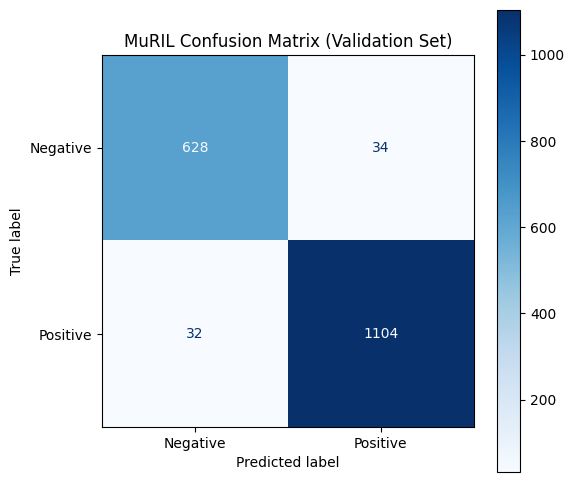

Confusion Matrix saved at: /content/drive/MyDrive/Assamese_Sentiment_Analysis/Results/Confusion Matrix/muril_confusion_matrix.svg


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d")

ax.set_title("MuRIL Confusion Matrix (Validation Set)")

# Save as SVG
cm_path = os.path.join(CONF_MATRIX_DIR, "muril_confusion_matrix.svg")
plt.savefig(cm_path, format="svg", bbox_inches="tight")

plt.show()

print(f"Confusion Matrix saved at: {cm_path}")


# ROC-AUC Curve and Score

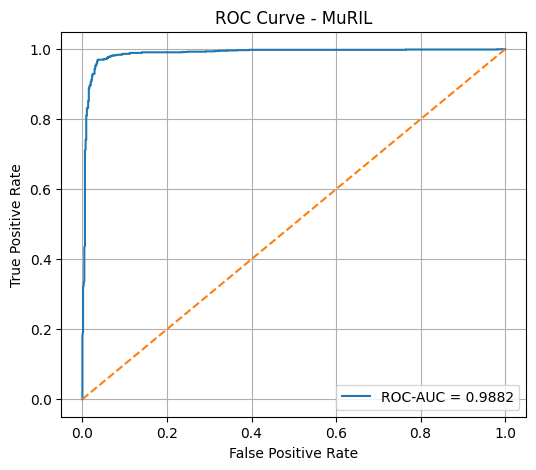

ROC Curve saved at: /content/drive/MyDrive/Assamese_Sentiment_Analysis/Results/muril_roc_curve.svg
ROC-AUC Score: 0.9881713810050637


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

roc_auc = roc_auc_score(y_true, y_probs)
fpr, tpr, _ = roc_curve(y_true, y_probs)

fig, ax = plt.subplots(figsize=(6, 5))

ax.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
ax.plot([0, 1], [0, 1], linestyle="--")

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve - MuRIL")
ax.legend()
ax.grid(True)

roc_path = os.path.join(RESULTS_DIR, "muril_roc_curve.svg")
plt.savefig(roc_path, format="svg", bbox_inches="tight")

plt.show()

print(f"ROC Curve saved at: {roc_path}")


print("ROC-AUC Score:", roc_auc)

# Cohen's Kappa Score

In [ ]:
from sklearn.metrics import cohen_kappa_score

kappa = cohen_kappa_score(y_true, y_pred)

print("Cohen's Kappa:", kappa)


Cohen's Kappa: 0.9210520013092802


# Training vs Validation Curves

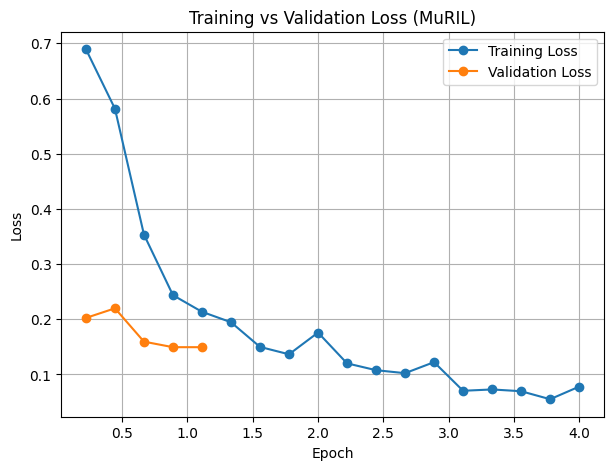

Training vs Validation curve saved at: /content/drive/MyDrive/Assamese_Sentiment_Analysis/Results/muril_training_validation_loss.svg


In [ ]:
train_loss = []
eval_loss = []
epochs = []

for log in trainer.state.log_history:
    if "loss" in log and "epoch" in log:
        train_loss.append(log["loss"])
        epochs.append(log["epoch"])
    if "eval_loss" in log:
        eval_loss.append(log["eval_loss"])

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(epochs[:len(train_loss)], train_loss, label="Training Loss", marker="o")
ax.plot(epochs[:len(eval_loss)], eval_loss, label="Validation Loss", marker="o")

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Training vs Validation Loss (MuRIL)")
ax.legend()
ax.grid(True)

# Save as SVG
loss_curve_path = os.path.join(RESULTS_DIR, "muril_training_validation_loss.svg")
plt.savefig(loss_curve_path, format="svg", bbox_inches="tight")

plt.show()

print(f"Training vs Validation curve saved at: {loss_curve_path}")


# Final Evaluation Metrics Table

In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = {
    "Model": "MuRIL",
    "Accuracy": accuracy_score(y_true, y_pred),
    "Macro Precision": precision_score(y_true, y_pred, average="macro"),
    "Macro Recall": recall_score(y_true, y_pred, average="macro"),
    "Macro F1": f1_score(y_true, y_pred, average="macro"),
    "ROC-AUC": roc_auc,
    "Cohen's Kappa": kappa
}

muril_results_df = pd.DataFrame([results])
muril_results_df


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,ROC-AUC,Cohen's Kappa
0,MuRIL,0.963293,0.960819,0.960236,0.960526,0.988171,0.921052


# Save the final Model

In [ ]:
MODEL_SAVE_PATH = "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Models/indicBERT/"

os.makedirs(MODEL_SAVE_PATH, exist_ok=True)

print("Model directory ready:", MODEL_SAVE_PATH)
